In [1]:
import xarray as xr
from pathlib import Path
from typing import List, Union
import glob
import pandas as pd
from datetime import datetime
import os

# Compute Mean Dynamic Topology (MDT)
This script is adapted to GLONET input GLORYS12 data.

## Define functions


In [2]:
# Load data from input list
def load_nc_files(data_list: List[Union[str, Path]], 
                  chunks: dict = None,
                  recursive: bool = True) -> List[xr.Dataset]:
    """
    Load netCDF files from a list containing directories and/or file paths.
    
    Parameters
    ----------
    data_list : List[Union[str, Path]]
        List of paths to directories or netCDF files
    chunks : dict, optional
        Chunk size for each dimension. Default: {'time': 'auto', 'x': 'auto', 'y': 'auto'}
    recursive : bool, default True
        If True, recursively search subdirectories for .nc files
        
    Returns
    -------
    List[xr.Dataset]
        List of loaded xarray Datasets with chunked data
        
    Example
    -------
    >>> datasets = load_nc_files(CONFIG['data_list'])
    >>> combined = xr.concat(datasets, dim='time')
    """
    
    if chunks is None:
        chunks = {'time': 30, 'lat': 360, 'lon': 360}
    
    nc_files = []
    datasets = []
    
    # Step 1: Collect all .nc files
    for element in data_list:
        path = Path(element)
        
        if path.is_dir():
            # Search for .nc files in directory (recursively or not)
            pattern = '**/*.nc' if recursive else '*.nc'
            found_files = list(path.glob(pattern))
            nc_files.extend(found_files)
            print(f"Found {len(found_files)} files in {element}")
            
        elif path.is_file() and path.suffix == '.nc':
            nc_files.append(path)
            print(f"Added file: {element}")
        else:
            print(f"Warning: {element} is not a directory or .nc file")
    
    # Step 2: Load netCDF files with chunking
    print(f"\nLoading {len(nc_files)} netCDF files...")
    for i, file_path in enumerate(nc_files, 1):
        try:
            ds = xr.open_dataset(file_path, chunks=chunks)
            datasets.append(ds)
            print(f"[{i}/{len(nc_files)}] Loaded: {file_path.name}")
        except Exception as e:
            print(f"Error loading {file_path}: {e}")
    
    return datasets

In [3]:
# Compute statistics across datasets
def compute_statistics(datasets_list: List[xr.Dataset]) -> xr.Dataset:
    """
    Compute mean across all datasets with memory-efficient weighted averaging.
    
    For datasets with different time dimensions, uses weighted average to ensure
    correct statistical representation.
    
    Parameters
    ----------
    datasets_list : List[xr.Dataset]
        List of xarray Datasets loaded with chunks
        
    Returns
    -------
    xr.Dataset
        Global mean dataset with metadata
    """

    
    mean_list = []
    time_counts = []
    time_ranges = []
    
    # Step 1: Compute mean for each dataset and track time dimension
    print("Computing means for each dataset...")
    for i, ds in enumerate(datasets_list, 1):
        # Get time count before computing mean (for weighted average)
        n_time = ds.dims.get('time', 1)
        time_counts.append(n_time)
        
        # Track time period for each dataset
        if 'time' in ds.dims and n_time > 0:
            time_min = ds['time'].values[0]
            time_max = ds['time'].values[-1]
            time_ranges.append((time_min, time_max))
        
        # Compute mean along time dimension and keep other dims
        mean = ds.mean(dim='time')
        mean_list.append(mean)
        print(f"[{i}/{len(datasets_list)}] Mean computed. Time steps: {n_time}")
    
    # Step 2: Concatenate all means along a new dimension for weighted averaging
    combined_means = xr.concat(mean_list, dim='dataset')
    
    # Step 3: Compute weighted mean across datasets
    weights = xr.DataArray(time_counts, dims=['dataset'], name='weights')
    global_mean = (combined_means * weights).sum('dataset') / weights.sum('dataset')
    
    print(f"\nGlobal mean computed. Total time steps: {sum(time_counts)}")
    
    # Step 4: Add metadata
    if time_ranges:
        time_min = pd.Timestamp(min(t[0] for t in time_ranges))
        time_max = pd.Timestamp(max(t[1] for t in time_ranges))
        
        global_mean.attrs['time_period_start'] = str(time_min)
        global_mean.attrs['time_period_end'] = str(time_max)
        global_mean.attrs['time_coverage'] = f"{time_min} to {time_max}"
    
    global_mean.attrs['total_timesteps'] = sum(time_counts)
    global_mean.attrs['num_datasets'] = len(datasets_list)
    global_mean.attrs['computation_method'] = 'weighted_mean_across_datasets'
    global_mean.attrs['computation_date'] = datetime.now().isoformat()
    global_mean.attrs['description'] = 'Global mean computed by averaging each dataset temporally, then combining with time-weighting'
    
    return global_mean


## Compute mdt
1. Read every netcdf file on `data_list`
2. compute mdt


In [4]:
# Define arguments
CONFIG = {
    "data_list" : ["/Odyssey/public/glonet/glorys12_2020-01-01_to_2020-12-31_init_states"
                   ],
    "output_dir": "/Odyssey/public/glonet/satistics"
}

output_file = str(os.getenv('OUTPUT_FILE', 'statistics_2020.nc'))

In [5]:
chunks = {'time': 30, 'lat': 360, 'lon': 360}

# Load the data
datasets_list = load_nc_files(CONFIG['data_list'], chunks=chunks)
print(f"\nSuccessfully loaded {len(datasets_list)} datasets")

# Compute statistics
global_mean = compute_statistics(datasets_list)


Found 13 files in /Odyssey/public/glonet/glorys12_2020-01-01_to_2020-12-31_init_states

Loading 13 netCDF files...


[1/13] Loaded: combined_input_2020-03-31_to_2020-04-29.nc
[2/13] Loaded: combined_input_2020-06-29_to_2020-07-28.nc


[3/13] Loaded: combined_input_2020-07-29_to_2020-08-27.nc
[4/13] Loaded: combined_input_2020-05-30_to_2020-06-28.nc
[5/13] Loaded: combined_input_2020-04-30_to_2020-05-29.nc


[6/13] Loaded: combined_input_2020-03-01_to_2020-03-30.nc
[7/13] Loaded: combined_input_2020-01-31_to_2020-02-29.nc
[8/13] Loaded: combined_input_2020-12-26_to_2020-12-31.nc


[9/13] Loaded: combined_input_2020-01-01_to_2020-01-30.nc
[10/13] Loaded: combined_input_2020-08-28_to_2020-09-26.nc


[11/13] Loaded: combined_input_2020-10-27_to_2020-11-25.nc
[12/13] Loaded: combined_input_2020-09-27_to_2020-10-26.nc


[13/13] Loaded: combined_input_2020-11-26_to_2020-12-25.nc

Successfully loaded 13 datasets
Computing means for each dataset...
[1/13] Mean computed. Time steps: 30
[2/13] Mean computed. Time steps: 30
[3/13] Mean computed. Time steps: 30
[4/13] Mean computed. Time steps: 30
[5/13] Mean computed. Time steps: 30
[6/13] Mean computed. Time steps: 30
[7/13] Mean computed. Time steps: 30
[8/13] Mean computed. Time steps: 6
[9/13] Mean computed. Time steps: 30
[10/13] Mean computed. Time steps: 30
[11/13] Mean computed. Time steps: 30
[12/13] Mean computed. Time steps: 30
[13/13] Mean computed. Time steps: 30

Global mean computed. Total time steps: 366


/tmp/ipykernel_2369244/3208866703.py:29: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  n_time = ds.dims.get('time', 1)
<frozen _collections_abc>:807: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_2369244/3208866703.py:29: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  n_time = ds.dims.get('time', 1)
<frozen _collections_abc>:807: FutureWarning: The return type of `Dataset.dims` w

In [6]:
global_mean

<xarray.Dataset> Size: 658MB
Dimensions:  (lat: 672, lon: 1440, ch: 85)
Coordinates:
  * lat      (lat) float64 5kB -78.0 -77.75 -77.5 -77.25 ... 89.25 89.5 89.75
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * ch       (ch) int64 680B 0 1 2 3 4 5 6 7 8 9 ... 76 77 78 79 80 81 82 83 84
Data variables:
    data     (ch, lat, lon) float64 658MB dask.array<chunksize=(85, 360, 360), meta=np.ndarray>
Attributes:
    time_period_start:   2020-01-01 00:00:00
    time_period_end:     2020-12-31 00:00:00
    time_coverage:       2020-01-01 00:00:00 to 2020-12-31 00:00:00
    total_timesteps:     366
    num_datasets:        13
    computation_method:  weighted_mean_across_datasets
    computation_date:    2026-04-26T13:39:43.082389
    description:         Global mean computed by averaging each dataset tempo...

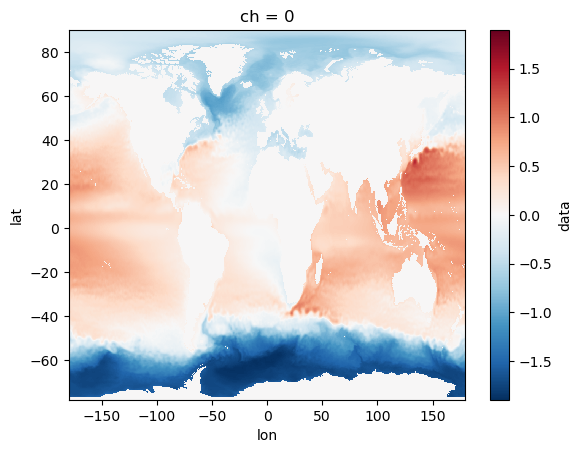

In [7]:
global_mean['data'].isel(ch=0).load().plot()

In [8]:
global_mean.attrs

{'time_period_start': '2020-01-01 00:00:00',
 'time_period_end': '2020-12-31 00:00:00',
 'time_coverage': '2020-01-01 00:00:00 to 2020-12-31 00:00:00',
 'total_timesteps': 366,
 'num_datasets': 13,
 'computation_method': 'weighted_mean_across_datasets',
 'computation_date': '2026-04-26T13:39:43.082389',
 'description': 'Global mean computed by averaging each dataset temporally, then combining with time-weighting'}

## Save statistics

In [9]:
os.makedirs(CONFIG['output_dir'], exist_ok=True)

global_mean.to_netcdf(f"{CONFIG['output_dir']}/{output_file}")
print(f"\nGlobal mean saved to < {CONFIG['output_dir']}/{output_file} >")


Global mean saved to < /Odyssey/public/glonet/satistics/statistics_2020.nc >
